# Phase 5 Out-of-time evaluation and monitoring

Frozen XGBoost, natural Production prevalence, no retraining or selection. Distinguish covariate, output, label and performance changes from concept drift.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
r=json.loads((ROOT/'artifacts/monitoring_summary.json').read_text(encoding='utf-8'))
freeze=json.loads((ROOT/'artifacts/production_monitoring_freeze.json').read_text(encoding='utf-8'))
display({k:freeze[k] for k in ['model_sha256','effective_iterations','threshold','top_fractions','window_width_hours']})
display(r['production'])

{'model_sha256': '44a20bc0e2abbd276ae94790db404248d2ab2c5d01025b00b2e4f935b6f220e4', 'effective_iterations': 24, 'threshold': 0.5, 'top_fractions': [0.001, 0.005, 0.01], 'window_width_hours': 72}

{'rows': 575590, 'frauds': 3736, 'step_min': 401, 'step_max': 743, 'metrics': {'observations': 575590, 'frauds': 3736, 'prevalence': 0.006490731249674247, 'pr_auc': 0.9998817696921924, 'roc_auc': 0.9999990261867279, 'precision_05': 1.0, 'recall_05': 0.9965203426124197, 'f1_05': 0.9982571390266792, 'f2_05': 0.9972143354582954, 'tp': 3723, 'fp': 0, 'tn': 571854, 'fn': 13, 'alerts': 3723, 'alert_rate': 0.00646814572873052, 'support_warning': '', 'k_0.1pct': 576, 'precision_top_0.1pct': 1.0, 'recall_top_0.1pct': 0.15417558886509636, 'k_0.5pct': 2878, 'precision_top_0.5pct': 1.0, 'recall_top_0.5pct': 0.7703426124197003, 'k_1pct': 5756, 'precision_top_1pct': 0.6490618485059069, 'recall_top_1pct': 1.0}}

## Out-of-time comparison

AP is prevalence-sensitive. Top0.1% capacity cannot capture more frauds than reviewed rows. Production is not an optimization set.

In [2]:
display(pd.read_csv(ROOT/'artifacts/production_model_comparison.csv'))
display(r['top_k_capacity_limits'])

,period,observations,frauds,prevalence,pr_auc,roc_auc,precision_05,recall_05,f1_05,f2_05,tp,fp,tn,fn,alerts,alert_rate,support_warning,k_0.1pct,precision_top_0.1pct,recall_top_0.1pct,k_0.5pct,precision_top_0.5pct,recall_top_0.5pct,k_1pct,precision_top_1pct,recall_top_1pct
0,Validation,1398242,868,0.000621,0.999919,1.000000,1.0,0.998848,0.999424,0.999078,867,0,1397374,1,867,0.000620,NaN,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.0
1,Production,575590,3736,0.006491,0.999882,0.999999,1.0,0.996520,0.998257,0.997214,3723,0,571854,13,3723,0.006468,NaN,576,1.000000,0.154176,2878,1.000000,0.770343,5756,0.649062,1.0


{'0.001': 0.15417558886509636, '0.005': 0.7703426124197003, '0.01': 1}

## Covariate drift

Separate statistical significance from practical magnitude. Step is structurally disjoint and excluded from counts. Within-type comparisons address mixture confounding. Rare-feature changes may remain operationally important below generic alert thresholds.

In [3]:
display(pd.read_csv(ROOT/'artifacts/data_drift_features.csv'))
display(pd.read_csv(ROOT/'artifacts/type_conditioned_drift.csv'))
display(r['evidently'])

,feature,reference_mean,current_mean,practical_threshold,structural_time,test,effect_metric,effect,p_value,psi,holm_p_value,statistical_shift,practically_material,drift_detected,psi_review
0,step,2.167302e+02,5.115102e+02,0.10,True,KS_asymptotic,KS_D,1.000000,0.000000e+00,12.537163,1.000000e+00,False,True,False,False
1,amount,1.813502e+05,1.648983e+05,0.10,False,KS_asymptotic,KS_D,0.021253,0.000000e+00,0.003489,0.000000e+00,True,False,False,False
2,oldbalanceOrg,8.447114e+05,7.250146e+05,0.10,False,KS_asymptotic,KS_D,0.031982,0.000000e+00,0.005501,0.000000e+00,True,False,False,False
3,oldbalanceDest,1.092353e+06,1.184639e+06,0.10,False,KS_asymptotic,KS_D,0.023272,0.000000e+00,0.003109,0.000000e+00,True,False,False,False
4,amount_to_oldbalanceOrg,8.233035e+01,7.551119e+01,0.10,False,KS_asymptotic,KS_D,0.037977,0.000000e+00,0.007376,0.000000e+00,True,False,False,False
5,orig_balance_zero,3.333307e-01,3.013499e-01,0.05,False,chi_square,total_variation,0.031981,0.000000e+00,NaN,0.000000e+00,True,False,False,False
6,orig_balance_emptied,7.579017e-04,6.311784e-03,0.05,False,chi_square,total_variation,0.005554,0.000000e+00,NaN,0.000000e+00,True,False,False,False
7,dest_is_merchant,3.367895e-01,3.517851e-01,0.05,False,chi_square,total_variation,0.014996,2.083207e-116,NaN,1.249924e-115,True,False,False,False
8,type_CASH_IN,2.196925e-01,2.222363e-01,0.05,False,chi_square,total_variation,0.002544,8.839989e-06,NaN,1.767998e-05,True,False,False,False
9,type_CASH_OUT,3.539114e-01,3.290606e-01,0.05,False,chi_square,total_variation,0.024851,2.534810e-310,NaN,1.774367e-309,True,False,False,False


,type,feature,reference_rows,production_rows,effect,method
0,CASH_IN,amount,1271367,127917,8.795977e-03,KS_D
1,CASH_IN,oldbalanceOrg,1271367,127917,4.232717e-02,KS_D
2,CASH_IN,oldbalanceDest,1271367,127917,1.330066e-02,KS_D
3,CASH_IN,amount_to_oldbalanceOrg,1271367,127917,3.073724e-02,KS_D
4,CASH_IN,orig_balance_emptied,1271367,127917,0.000000e+00,TV
5,CASH_OUT,amount,2048096,189404,3.717810e-02,KS_D
6,CASH_OUT,oldbalanceOrg,2048096,189404,6.124949e-02,KS_D
7,CASH_OUT,oldbalanceDest,2048096,189404,2.640155e-02,KS_D
8,CASH_OUT,amount_to_oldbalanceOrg,2048096,189404,6.125095e-02,KS_D
9,CASH_OUT,orig_balance_emptied,2048096,189404,8.715714e-03,TV


{'version': '0.7.23', 'status': 'COMPLETE', 'reference_sample_rows': 25000, 'current_sample_rows': 25000, 'method': 'PSI threshold 0.2 on reproducible uniform samples; supplementary, not the full-data primary decision', 'files': ['evidently_data_drift.html', 'evidently_prediction_drift.html']}

## Prediction and performance monitoring

Changed scores do not automatically imply concept drift. Recall point estimate falls modestly; inspect actual missed fraud and support rather than near-one aggregate scores.

,period,mean,median,p01,p10,p90,p99,p999,score_ge_05,alert_rate,score_ge_09_rate
0,Reference_Development,0.004413,0.003591,0.003586,0.00359,0.003632,0.004074,0.034012,4444,0.000768,0.000767
1,Validation,0.004242,0.003591,0.003586,0.00359,0.003632,0.003919,0.019386,867,0.000620,0.000619
2,Production,0.009920,0.003591,0.003586,0.00359,0.003632,0.004595,0.979050,3723,0.006468,0.006454


,window,step_min,step_max,observations,frauds,prevalence,pr_auc,roc_auc,precision_05,recall_05,f1_05,f2_05,tp,fp,tn,fn,alerts,alert_rate,support_warning,k_0.1pct,precision_top_0.1pct,recall_top_0.1pct,k_0.5pct,precision_top_0.5pct,recall_top_0.5pct,k_1pct,precision_top_1pct,recall_top_1pct
0,0,401,472,243078,806,0.003316,0.999918,1.000000,1.0,0.997519,0.998758,0.998014,804,0,242272,2,804,0.003308,NaN,244,1.0,0.302730,1216,0.662829,1.000000,2431,0.331551,1.000000
1,1,473,544,111182,742,0.006674,1.000000,1.000000,1.0,1.000000,1.000000,1.000000,742,0,110440,0,742,0.006674,NaN,112,1.0,0.150943,556,1.000000,0.749326,1112,0.667266,1.000000
2,2,545,616,125005,776,0.006208,0.999967,1.000000,1.0,0.997423,0.998710,0.997937,774,0,124229,2,774,0.006192,NaN,126,1.0,0.162371,626,1.000000,0.806701,1251,0.620304,1.000000
3,3,617,688,62572,770,0.012306,0.999726,0.999996,1.0,0.993506,0.996743,0.994798,765,0,61802,5,765,0.012226,NaN,63,1.0,0.081818,313,1.000000,0.406494,626,1.000000,0.812987
4,4,689,743,33753,642,0.019021,0.999983,1.000000,1.0,0.993769,0.996875,0.995009,638,0,33111,4,638,0.018902,NaN,34,1.0,0.052960,169,1.000000,0.263240,338,1.000000,0.526480


,period,type,observations,frauds,prevalence,pr_auc,roc_auc,precision_05,recall_05,f1_05,f2_05,tp,fp,tn,fn,alerts,alert_rate,support_warning,k_0.1pct,precision_top_0.1pct,recall_top_0.1pct,k_0.5pct,precision_top_0.5pct,recall_top_0.5pct,k_1pct,precision_top_1pct,recall_top_1pct
0,Validation,CASH_IN,310631,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0,0,310631,0,0,0.000000,no_positive_labels,311,0.000000,NaN,1554,0.000000,NaN,3107,0.000000,NaN
1,Validation,CASH_OUT,492118,434,0.000882,0.999696,1.000000,1.0,0.997696,0.998847,0.998156,433,0,491684,1,433,0.000880,NaN,493,0.878296,0.997696,2461,0.176351,1.000000,4922,0.088176,1.000000
2,Validation,DEBIT,9981,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0,0,9981,0,0,0.000000,no_positive_labels,10,0.000000,NaN,50,0.000000,NaN,100,0.000000,NaN
3,Validation,PAYMENT,466937,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0,0,466937,0,0,0.000000,no_positive_labels,467,0.000000,NaN,2335,0.000000,NaN,4670,0.000000,NaN
4,Validation,TRANSFER,118575,434,0.003660,1.000000,1.000000,1.0,1.000000,1.000000,1.000000,434,0,118141,0,434,0.003660,NaN,119,1.000000,0.274194,593,0.731872,1.000000,1186,0.365936,1.000000
5,Production,CASH_IN,127917,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0,0,127917,0,0,0.000000,no_positive_labels,128,0.000000,NaN,640,0.000000,NaN,1280,0.000000,NaN
6,Production,CASH_OUT,189404,1868,0.009863,0.999867,0.999999,1.0,0.993576,0.996778,0.994854,1856,0,187536,12,1856,0.009799,NaN,190,1.000000,0.101713,948,1.000000,0.507495,1895,0.983113,0.997323
7,Production,DEBIT,4316,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0,0,4316,0,0,0.000000,no_positive_labels,5,0.000000,NaN,22,0.000000,NaN,44,0.000000,NaN
8,Production,PAYMENT,202484,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0,0,202484,0,0,0.000000,no_positive_labels,203,0.000000,NaN,1013,0.000000,NaN,2025,0.000000,NaN
9,Production,TRANSFER,51469,1868,0.036294,0.999859,0.999993,1.0,0.999465,0.999732,0.999572,1867,0,49601,1,1867,0.036274,NaN,52,1.000000,0.027837,258,1.000000,0.138116,515,1.000000,0.275696


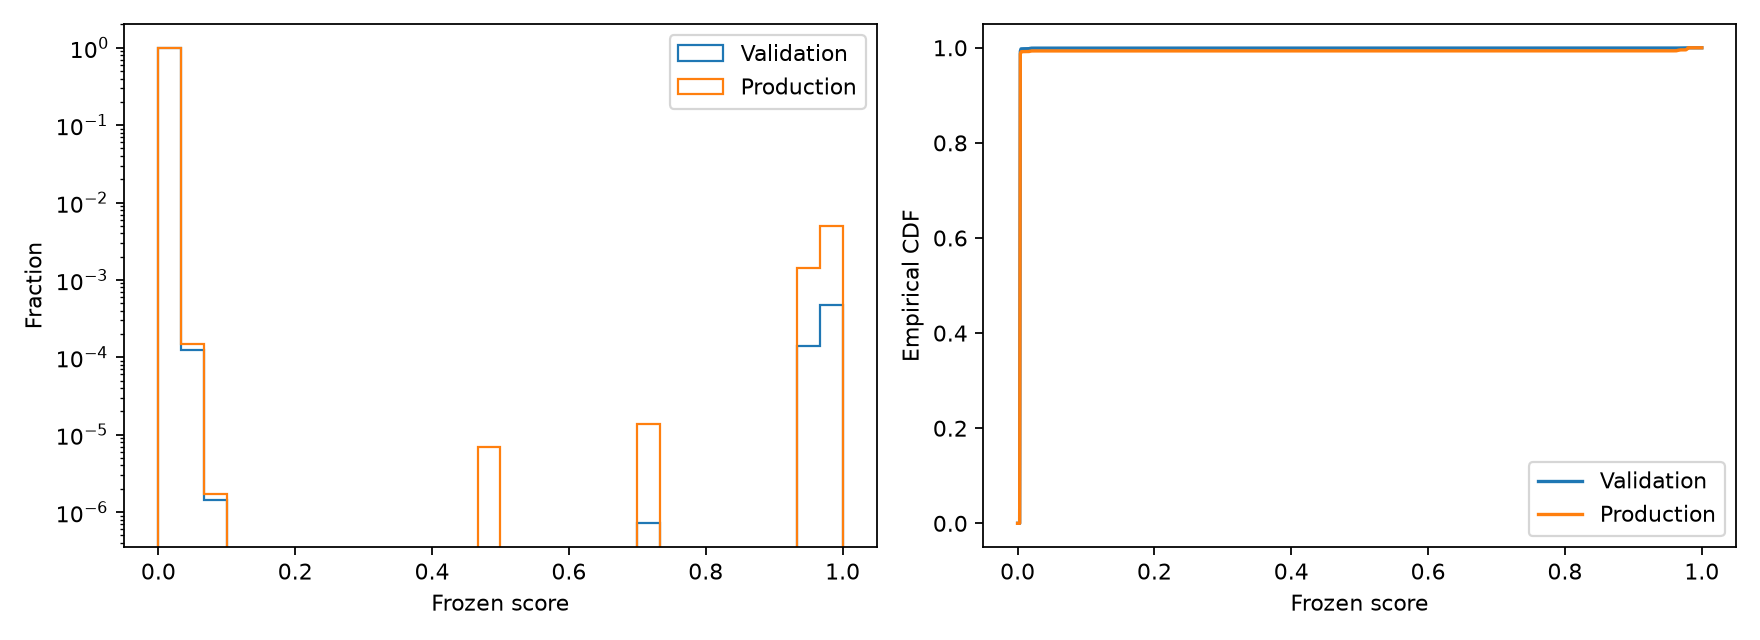

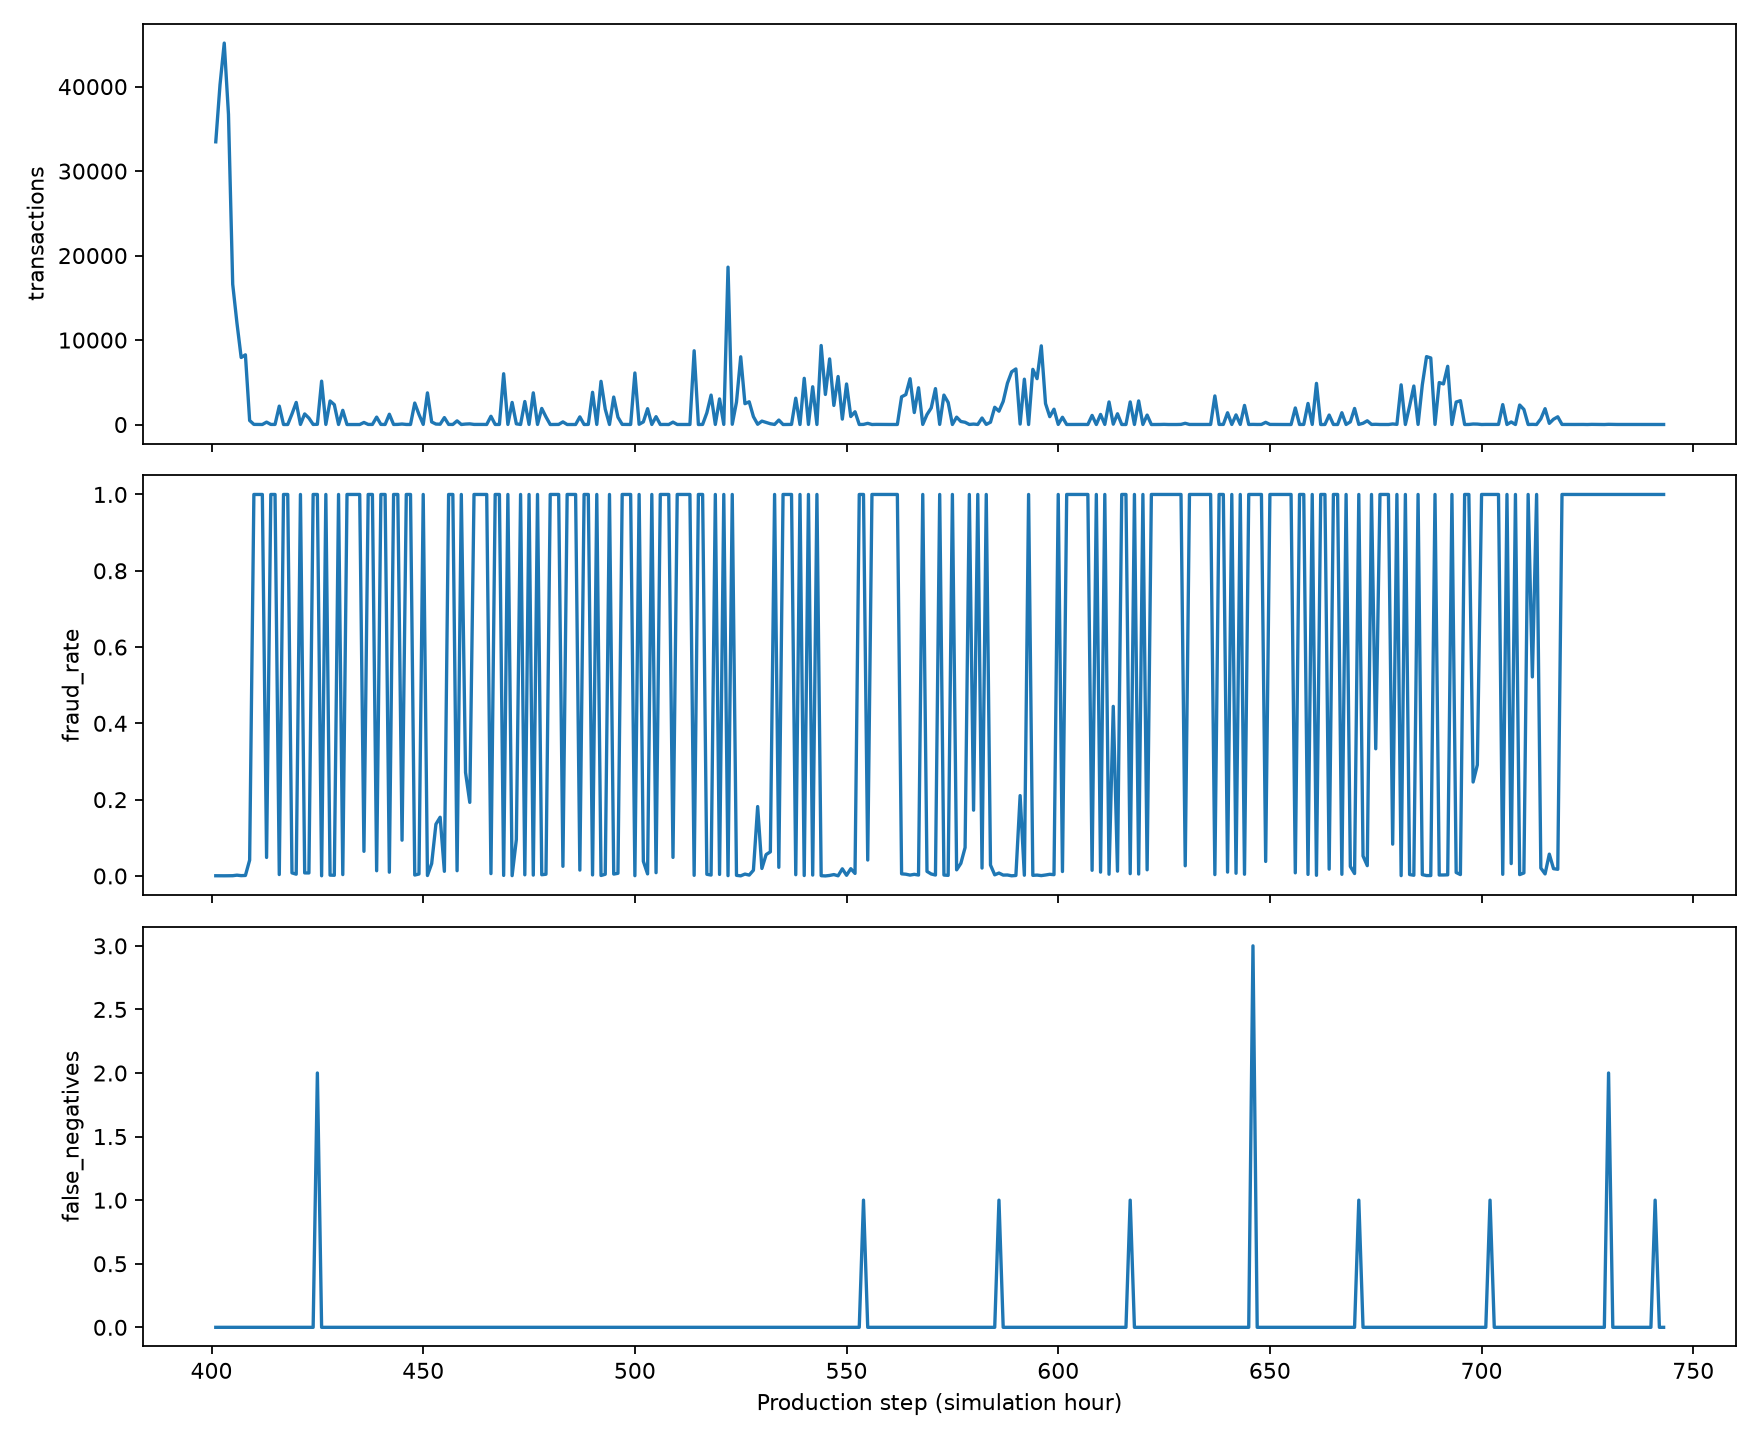

In [4]:
display(pd.read_csv(ROOT/'artifacts/monitoring_scores.csv'))
display(pd.read_csv(ROOT/'artifacts/monitoring_windows.csv'))
display(pd.read_csv(ROOT/'artifacts/monitoring_by_type.csv'))
for name in ['score_distributions.png','production_evolution.png']:
    display(Image(filename=str(ROOT/'reports/figures/monitoring'/name)))

## Atypical cases and conditional uncertainty

12 amount-zero frauds are missed at 0.5. Cases at 0.499480 remain errors; Production must not motivate a threshold change. Coarse conditional label shifts do not establish full P(Y|X) change.

In [5]:
display(pd.read_csv(ROOT/'artifacts/monitoring_relation_checks.csv'))
display(pd.read_csv(ROOT/'artifacts/monitoring_atypical_cases.csv'))
display(r['concept_drift'])
display(r['mlflow'])

,period,rule,observations,frauds,prevalence,pr_auc,roc_auc,precision_05,recall_05,f1_05,f2_05,tp,fp,tn,fn,alerts,alert_rate,support_warning,k_0.1pct,precision_top_0.1pct,recall_top_0.1pct,k_0.5pct,precision_top_0.5pct,recall_top_0.5pct,k_1pct,precision_top_1pct,recall_top_1pct
0,Validation,emptied_1,852,852,1.000000,1.000000,NaN,1.0,1.000000,1.000000,1.000000,852,0,0,0,852,1.000000,no_negative_labels,1,1.000000,0.001174,5,1.000000,0.005869,9,1.000000,0.010563
1,Validation,emptied_0,1397390,16,0.000011,0.949695,0.999998,1.0,0.937500,0.967742,0.949367,15,0,1397374,1,15,0.000011,few_positives_below_30,1398,0.011445,1.000000,6987,0.002290,1.000000,13974,0.001145,1.000000
2,Validation,amount_zero,1,1,1.000000,1.000000,NaN,NaN,0.000000,0.000000,0.000000,0,0,0,1,0,0.000000,no_negative_labels,1,1.000000,1.000000,1,1.000000,1.000000,1,1.000000,1.000000
3,Validation,positive_balance_ratio_near_1,852,852,1.000000,1.000000,NaN,1.0,1.000000,1.000000,1.000000,852,0,0,0,852,1.000000,no_negative_labels,1,1.000000,0.001174,5,1.000000,0.005869,9,1.000000,0.010563
4,Production,emptied_1,3633,3633,1.000000,1.000000,NaN,1.0,1.000000,1.000000,1.000000,3633,0,0,0,3633,1.000000,no_negative_labels,4,1.000000,0.001101,19,1.000000,0.005230,37,1.000000,0.010184
5,Production,emptied_0,571957,103,0.000180,0.962949,0.999965,1.0,0.873786,0.932642,0.896414,90,0,571854,13,90,0.000157,NaN,572,0.178322,0.990291,2860,0.036014,1.000000,5720,0.018007,1.000000
6,Production,amount_zero,12,12,1.000000,1.000000,NaN,NaN,0.000000,0.000000,0.000000,0,0,0,12,0,0.000000,no_negative_labels,1,1.000000,0.083333,1,1.000000,0.083333,1,1.000000,0.083333
7,Production,positive_balance_ratio_near_1,3633,3633,1.000000,1.000000,NaN,1.0,1.000000,1.000000,1.000000,3633,0,0,0,3633,1.000000,no_negative_labels,4,1.000000,0.001101,19,1.000000,0.005230,37,1.000000,0.010184


,period,category,period_row_index,label,score,prediction_05,step,amount,oldbalanceOrg,oldbalanceDest,amount_to_oldbalanceOrg,orig_balance_zero,orig_balance_emptied,dest_is_merchant,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,type_UNKNOWN
0,Validation,fraud_amount_zero,1174926,1,0.057349,0,387.0,0.000000e+00,0.0,7.970766e+06,0.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,Validation,fraud_outside_emptying,644394,1,0.967110,1,354.0,1.000000e+07,19299230.0,0.000000e+00,0.518155,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,Validation,fraud_outside_emptying,770843,1,0.962584,1,357.0,1.000000e+07,10653152.0,0.000000e+00,0.938689,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,Validation,fraud_outside_emptying,790223,1,0.962584,1,359.0,1.000000e+07,12056779.0,0.000000e+00,0.829409,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,Validation,fraud_outside_emptying,799030,1,0.967110,1,362.0,1.000000e+07,17677120.0,0.000000e+00,0.565703,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,Validation,fraud_outside_emptying,832362,1,0.962584,1,370.0,1.000000e+07,11653144.0,0.000000e+00,0.858137,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6,Validation,fraud_outside_emptying,1174717,1,0.958965,1,386.0,1.000000e+07,21975272.0,0.000000e+00,0.455057,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7,Validation,fraud_outside_emptying,1174719,1,0.962584,1,386.0,1.000000e+07,11975272.0,0.000000e+00,0.835054,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8,Validation,fraud_outside_emptying,1174917,1,0.716314,1,387.0,1.000000e+07,44892192.0,0.000000e+00,0.222756,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9,Validation,fraud_outside_emptying,1174919,1,0.958965,1,387.0,1.000000e+07,34892192.0,0.000000e+00,0.286597,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Concept drift not conclusively established.

{'run_id': 'c8f4505245614c4e97bd931fb75f4749', 'experiment_id': '1', 'tracking_uri': 'sqlite:///./mlruns/mlflow.db', 'historical_hashes': {'7fa24d6ea79f4b6d8f62a07236a351f9': '453ccd888c5cc457b7124a8ae45d5e6238cfd540ba64414618802b310ec9c3b6', '33845df18b4a48288e116b0027e6b946': '09a40d866fb9cfbce053f292aed8bf7b89b622107c10c8d41505bbd85f294f89', 'ac0682a9e54a4f75a3b63cd052a1fdc6': '3ab569a3165c503ee90cdd02017172d93ad01e67491b3585b8b75f8e62bf9a6c', 'e5b6ee1abaca488095f18010663e5166': 'a907fd98739d8429e8d026ae4d1f0368e514806e82b1730f56198987e4344959', 'd18fbdce26b74ebf97073b110eca54c2': '8d2f6dd48340297dc42609e20880dffe97dbc937ab74202ca6f8293db84b27bc', 'c59c39c3a2c94ac09c84ab4910a6971b': 'd4af3dc155bc6221ae8e8104cfe2a38cdaf72b009867f02ec5d76b41972c7fd9', 'e2ed011b3ba047e7bded7d278c8b0115': '762b8bdb9458cfe7c0be43156ec86b601715cc2a0760ec02027aee94533b280e', 'ec2c94b13a2f4c8b9d28731222d400a7': '65988ac2af5fc123a45bb258733b6a49e6c345146db18e411b4145651d533802', 'dfeb3a494f8d46a184212798089f

## Conclusions and complete report

Concept drift not conclusively established. No new champion, calibration or threshold. Phase 6 requires separate authorization.

In [6]:
display(Markdown((ROOT/'PHASE_5_MONITORING_REPORT.md').read_text(encoding='utf-8')))

# Phase 5 Production Evaluation and Monitoring Report

## 1 Executive summary
Frozen XGBoost tuned evaluated out of time on 575,590 Production transactions and 3,736 frauds. AP 0.999881770, ROC-AUC 0.999999026, precision 1.000000, recall 0.996520, F2 0.997214. TP 3723, FP 0, TN 571854, FN 13. No model, features, calibration, threshold or champion selection changed after viewing Production.

There are 12 statistically shifted non-time features, but 0 pass both statistical and predeclared practical alert criteria. This is not evidence that all changes are operationally irrelevant: rare fraud-linked features and alert burden increased substantially. Prediction distribution changes and a modest observed recall decline are reported separately from concept drift. **Concept drift not conclusively established.**

## 2 Received state frozen identity and verification
Reviewed all four previous phase reports, feature catalog, Phase 3 identity/configuration, native models, existing modules/scripts/tests/notebooks, pyproject and Git before modifications. Existing uncommitted work preserved on development. No prior training or optimization was repeated.

Before first Production access, scripts/freeze_monitoring_model.py loaded the exact native XGBoost and reproduced every saved Validation metric to tolerance 1e-10. Freeze records model SHA256 `44a20bc0e2abbd276ae94790db404248d2ab2c5d01025b00b2e4f935b6f220e4`, source run `1d353308f1e3427094a221667f3da9de`, fourteen ordered MODEL_COLUMNS, features.py hash, recorded training parameters and native inference configuration. Best_iteration+1=24; the original saved artifact still contains 44 rounds but inference uses only the 24 effective rounds. No retraining or parameter-setting call occurs. Native serialization need not retain training constructor defaults; hash and reproduced metrics authenticate the learned artifact and its source-run parameter metadata.

Training parameters:
```json
{
  "n_estimators": 148,
  "max_depth": 6,
  "learning_rate": 0.1469541059356907,
  "min_child_weight": 3.532871354926938,
  "subsample": 0.9942734367531818,
  "colsample_bytree": 0.8825728131957696,
  "reg_alpha": 0.02165779390916417,
  "reg_lambda": 0.5395608952674368,
  "gamma": 0.9674364834653933,
  "scale_pos_weight": 10.0
}
```

Freeze also fixes reference threshold 0.5, Top-K capacities 0.1%, 0.5%, 1%, 72-hour windows anchored at step 401, support warning threshold 30 positives, drift rules and reference-only histogram boundaries. Freeze artifact SHA256 `450f59d14924daadee8db2c4e85c8ac0c6cee79ea10a4104cba46f2eb7310726`. Model hash and earlier phase fingerprints rechecked after evaluation. Production is used only for retrospective evaluation and monitoring, never selection, tuning, calibration, early stopping or changes to the model.

## 3 Temporal definitions size and prevalence
step is treated as a simulation hour for this academic analysis, not mapped to a real calendar. Reference/Development: steps 1–400, 5,787,030 rows, 4,477 frauds, prevalence 0.077363%. Validation: steps 321–400. Actual Production range: 401–743, not the proposed upper bound 744. Production prevalence 0.649073%, approximately 8.390 times Reference.

Only one chunked raw CSV scan selects Production. Reference uses existing development matrices; principal feature engineering is reused without fitting or altering it. No duplicate raw CSV, full-score export or giant new matrices are saved. Validation is a development holdout previously reused for tuning; Production is the first out-of-time evaluation after model freeze, not an optimization set. Target labels simulate retrospective availability and may arrive later in a real system.

## 4 Validation vs Production and operational ranking
| period | observations | frauds | prevalence | pr_auc | roc_auc | precision_05 | recall_05 | f1_05 | f2_05 | tp | fp | tn | fn |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Validation | 1398242 | 868 | 0.00062078 | 0.99991859 | 0.99999997 | 1.00000000 | 0.99884793 | 0.99942363 | 0.99907813 | 867 | 0 | 1397374 | 1 |
| Production | 575590 | 3736 | 0.00649073 | 0.99988177 | 0.99999903 | 1.00000000 | 0.99652034 | 0.99825714 | 0.99721434 | 3723 | 0 | 571854 | 13 |

AP is non-interpolated sklearn Average Precision. It depends on class prevalence and the distribution of score ranks; comparisons across differing prevalence require caution. ROC-AUC is secondary; near-one ROC values must not hide actual error counts. Precision/Recall/F1/F2 use the fixed reference threshold 0.5, not a final production threshold. Natural prevalence is preserved.

| period | k_0.1pct | precision_top_0.1pct | recall_top_0.1pct | k_0.5pct | precision_top_0.5pct | recall_top_0.5pct | k_1pct | precision_top_1pct | recall_top_1pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Validation | 1399 | 0.62044317 | 1.00000000 | 6992 | 0.12414188 | 1.00000000 | 13983 | 0.06207538 | 1.00000000 |
| Production | 576 | 1.00000000 | 0.15417559 | 2878 | 1.00000000 | 0.77034261 | 5756 | 0.64906185 | 1.00000000 |

Top0.1% in Production reviews 576 observations while there are 3,736 frauds. Its maximum possible recall at that capacity is 15.417559%, and the frozen model reaches that bound with precision 1.0. The drop from Validation Top0.1% recall 100% to Production 15.417559% is therefore a capacity/prevalence effect rather than evidence of poor top-risk ranking. Top0.5% also saturates its bound, while Top1% captures all frauds. Stable original row order breaks score ties as in prior phases. Ranking is global retrospective review capacity, not a deployed streaming review policy.

## 5 Data and covariate drift
Primary full-data comparison: Reference <=400 vs Production >=401. Continuous variables use two-sample asymptotic KS, binary indicators use chi-square and total variation. Holm adjustment applies to thirteen non-time features. A primary alert requires adjusted p<0.05 **and** KS D>=0.10 for numeric features or TV>=0.05 for binary features. PSI uses reference-only decile boundaries, deduplicated for zero-inflated distributions and Jeffreys pseudocount 0.5 per bin; PSI>=0.20 is a separate review flag. These thresholds are documented engineering conventions, not universal statistical laws or cost-validated fraud limits.

| feature | reference_mean | current_mean | practical_threshold | structural_time | test | effect_metric | effect | p_value | psi | holm_p_value | statistical_shift | practically_material | drift_detected | psi_review |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| step | 216.73017213 | 511.51023298 | 0.10000000 | True | KS_asymptotic | KS_D | 1.00000000 | 0.00000000 | 12.53716282 | 1.00000000 | False | True | False | False |
| amount | 181350.21196296 | 164898.32637851 | 0.10000000 | False | KS_asymptotic | KS_D | 0.02125341 | 0.00000000 | 0.00348871 | 0.00000000 | True | False | False | False |
| oldbalanceOrg | 844711.39054645 | 725014.60596192 | 0.10000000 | False | KS_asymptotic | KS_D | 0.03198171 | 0.00000000 | 0.00550084 | 0.00000000 | True | False | False | False |
| oldbalanceDest | 1092353.06612969 | 1184639.19303915 | 0.10000000 | False | KS_asymptotic | KS_D | 0.02327234 | 0.00000000 | 0.00310904 | 0.00000000 | True | False | False | False |
| amount_to_oldbalanceOrg | 82.33035321 | 75.51119036 | 0.10000000 | False | KS_asymptotic | KS_D | 0.03797677 | 0.00000000 | 0.00737589 | 0.00000000 | True | False | False | False |
| orig_balance_zero | 0.33333074 | 0.30134992 | 0.05000000 | False | chi_square | total_variation | 0.03198082 | 0.00000000 | undefined | 0.00000000 | True | False | False | False |
| orig_balance_emptied | 0.00075790 | 0.00631178 | 0.05000000 | False | chi_square | total_variation | 0.00555388 | 0.00000000 | undefined | 0.00000000 | True | False | False | False |
| dest_is_merchant | 0.33678951 | 0.35178512 | 0.05000000 | False | chi_square | total_variation | 0.01499561 | 0.00000000 | undefined | 0.00000000 | True | False | False | False |
| type_CASH_IN | 0.21969248 | 0.22223631 | 0.05000000 | False | chi_square | total_variation | 0.00254383 | 0.00000884 | undefined | 0.00001768 | True | False | False | False |
| type_CASH_OUT | 0.35391142 | 0.32906062 | 0.05000000 | False | chi_square | total_variation | 0.02485080 | 0.00000000 | undefined | 0.00000000 | True | False | False | False |
| type_DEBIT | 0.00641365 | 0.00749839 | 0.05000000 | False | chi_square | total_variation | 0.00108474 | 0.00000000 | undefined | 0.00000000 | True | False | False | False |
| type_PAYMENT | 0.33678951 | 0.35178512 | 0.05000000 | False | chi_square | total_variation | 0.01499561 | 0.00000000 | undefined | 0.00000000 | True | False | False | False |
| type_TRANSFER | 0.08319293 | 0.08941955 | 0.05000000 | False | chi_square | total_variation | 0.00622662 | 0.00000000 | undefined | 0.00000000 | True | False | False | False |
| type_UNKNOWN | 0.00000000 | 0.00000000 | 0.05000000 | False | chi_square | total_variation | 0.00000000 | 1.00000000 | undefined | 1.00000000 | False | False | False | False |

step has KS D=1 because the time periods are disjoint; it is displayed as structural separation and excluded from alert counts. type_UNKNOWN is constant, with no distribution shift. P-values shown as zero can reflect numerical underflow at very large support, not literally zero probability. The largest non-time distances are modest under these fixed rules. In particular the rare orig_balance_emptied feature changes by roughly half a percentage point, potentially important for fraud workload despite falling below a generic 5-percentage-point TV threshold. Do not interpret zero primary alerts as no covariate shift or no operational concern. Temporal dependence of simulated transactions limits iid significance interpretations; effect sizes and domain context are essential.

## 6 Transaction mixture and within-type changes
Overall transaction-type TV distance 0.024851. Type composition changes can drive shifts in amount, balance and scores without a changed mechanism within a transaction type. The following within-type distances provide contextual diagnostics, not another set of unadjusted alert claims:

| type | feature | reference_rows | production_rows | effect | method |
| --- | --- | --- | --- | --- | --- |
| CASH_IN | amount | 1271367 | 127917 | 0.00879598 | KS_D |
| CASH_IN | oldbalanceOrg | 1271367 | 127917 | 0.04232717 | KS_D |
| CASH_IN | oldbalanceDest | 1271367 | 127917 | 0.01330066 | KS_D |
| CASH_IN | amount_to_oldbalanceOrg | 1271367 | 127917 | 0.03073724 | KS_D |
| CASH_IN | orig_balance_emptied | 1271367 | 127917 | 0.00000000 | TV |
| CASH_OUT | amount | 2048096 | 189404 | 0.03717810 | KS_D |
| CASH_OUT | oldbalanceOrg | 2048096 | 189404 | 0.06124949 | KS_D |
| CASH_OUT | oldbalanceDest | 2048096 | 189404 | 0.02640155 | KS_D |
| CASH_OUT | amount_to_oldbalanceOrg | 2048096 | 189404 | 0.06125095 | KS_D |
| CASH_OUT | orig_balance_emptied | 2048096 | 189404 | 0.00871571 | TV |
| DEBIT | amount | 37116 | 4316 | 0.15214670 | KS_D |
| DEBIT | oldbalanceOrg | 37116 | 4316 | 0.08503928 | KS_D |
| DEBIT | oldbalanceDest | 37116 | 4316 | 0.02704775 | KS_D |
| DEBIT | amount_to_oldbalanceOrg | 37116 | 4316 | 0.08578826 | KS_D |
| DEBIT | orig_balance_emptied | 37116 | 4316 | 0.00000000 | TV |
| PAYMENT | amount | 1949011 | 202484 | 0.01998633 | KS_D |
| PAYMENT | oldbalanceOrg | 1949011 | 202484 | 0.02170974 | KS_D |
| PAYMENT | oldbalanceDest | 1949011 | 202484 | 0.00000000 | KS_D |
| PAYMENT | amount_to_oldbalanceOrg | 1949011 | 202484 | 0.02590325 | KS_D |
| PAYMENT | orig_balance_emptied | 1949011 | 202484 | 0.00000051 | TV |
| TRANSFER | amount | 481440 | 51469 | 0.05854875 | KS_D |
| TRANSFER | oldbalanceOrg | 481440 | 51469 | 0.01471055 | KS_D |
| TRANSFER | oldbalanceDest | 481440 | 51469 | 0.03138573 | KS_D |
| TRANSFER | amount_to_oldbalanceOrg | 481440 | 51469 | 0.02931023 | KS_D |
| TRANSFER | orig_balance_emptied | 481440 | 51469 | 0.03002663 | TV |

## 7 Prediction and output distribution monitoring
| period | mean | median | p01 | p10 | p90 | p99 | p999 | score_ge_05 | alert_rate | score_ge_09_rate |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Reference_Development | 0.00441260 | 0.00359135 | 0.00358555 | 0.00359012 | 0.00363166 | 0.00407427 | 0.03401220 | 4444 | 0.00076792 | 0.00076741 |
| Validation | 0.00424241 | 0.00359122 | 0.00358555 | 0.00359012 | 0.00363166 | 0.00391926 | 0.01938598 | 867 | 0.00062006 | 0.00061935 |
| Production | 0.00992040 | 0.00359122 | 0.00358555 | 0.00359012 | 0.00363166 | 0.00459496 | 0.97905046 | 3723 | 0.00646815 | 0.00645425 |

Frozen score KS: Reference vs Production D=0.089176, p=0; Validation vs Production D=0.033062, p=0. Means and upper-tail percentiles rise, while medians remain similar. Validation alert rate 0.062006% vs Production 0.646815%, approximately 10.431 times. A higher alert burden is operationally meaningful even when broad distribution distances are small. Scores are outputs of the weighted frozen model, not calibrated fraud probabilities. Prediction drift is not automatically concept drift or model deterioration. The learned model artifact itself did not drift or change.

## 8 Performance monitoring and evidence
Observed recall decreases by 0.232758 percentage points, from one FN among 868 frauds to thirteen FN among 3,736. Precision remains 1.0 with no FP; F2 decreases modestly. These are observed performance differences, not a claim of established stochastic degradation.

Descriptive 95% Wilson intervals:
| period | recall | recall_ci_low | recall_ci_high | fpr_ci_low | fpr_ci_high |
| --- | --- | --- | --- | --- | --- |
| Validation | 0.99884793 | 0.99350326 | 0.99979660 | 0.00000000 | 0.00000275 |
| Production | 0.99652034 | 0.99405537 | 0.99796529 | 0.00000000 | 0.00000672 |

A two-sided Fisher comparison of FN vs TP between periods gives p=0.490642. This simple labeled comparison is descriptive, assumes exchangeable/independent observations and does not control for feature mixture or temporal clustering. It is not proof of unchanged performance when non-significant, nor proof of concept drift. AP lacks an independent confidence interval here; do not fabricate statistical superiority or equivalence from its small change. Larger business costs of missed fraud may matter despite small aggregate metric changes.

## 9 Prevalence shift and concept drift
A descriptive increase in P(Y) is established in these simulated periods. A changed P(Y) does not by itself establish changed P(Y|X), and classical pure label shift would additionally require stable P(X|Y), which is not established here. Covariate and prediction shifts are evaluated separately. Coarse feature-target relation checks:

| period | rule | observations | frauds | prevalence | pr_auc | precision_05 | recall_05 | fn | support_warning |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Validation | emptied_1 | 852 | 852 | 1.00000000 | 1.00000000 | 1.00000000 | 1.00000000 | 0 | no_negative_labels |
| Validation | emptied_0 | 1397390 | 16 | 0.00001145 | 0.94969512 | 1.00000000 | 0.93750000 | 1 | few_positives_below_30 |
| Validation | amount_zero | 1 | 1 | 1.00000000 | 1.00000000 | undefined | 0.00000000 | 1 | no_negative_labels |
| Validation | positive_balance_ratio_near_1 | 852 | 852 | 1.00000000 | 1.00000000 | 1.00000000 | 1.00000000 | 0 | no_negative_labels |
| Production | emptied_1 | 3633 | 3633 | 1.00000000 | 1.00000000 | 1.00000000 | 1.00000000 | 0 | no_negative_labels |
| Production | emptied_0 | 571957 | 103 | 0.00018008 | 0.96294918 | 1.00000000 | 0.87378641 | 13 | undefined |
| Production | amount_zero | 12 | 12 | 1.00000000 | 1.00000000 | undefined | 0.00000000 | 12 | no_negative_labels |
| Production | positive_balance_ratio_near_1 | 3633 | 3633 | 1.00000000 | 1.00000000 | 1.00000000 | 1.00000000 | 0 | no_negative_labels |

Changes in P(Y|a coarse rule) do not establish changes conditional on the full feature vector: within-group covariate composition can change, and performance was selected on Development. Formal conditional change testing or an independent design is not supplied. **Concept drift not conclusively established.** Do not use ambiguous model drift terminology; this report explicitly describes outputs, metric differences and immutable artifact identity.

## 10 Fixed temporal windows and evolution
Windows are 72 simulation hours anchored at 401, chosen before Production. Final window is shortened at real max step 743. No window boundary was selected for favorable results. Support and undefined metrics are preserved; AP/recall are undefined with no positives, ROC-AUC with a single class, and precision with no alerts. Few positives (<30) produce explicit warnings; all-positive windows have trivial AP and a warning. No empty/artificial balanced windows are invented.

| window | step_min | step_max | observations | frauds | prevalence | pr_auc | roc_auc | precision_05 | recall_05 | f2_05 | fp | fn | support_warning |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 401 | 472 | 243078 | 806 | 0.00331581 | 0.99991835 | 0.99999979 | 1.00000000 | 0.99751861 | 0.99801390 | 0 | 2 | undefined |
| 1 | 473 | 544 | 111182 | 742 | 0.00667374 | 1.00000000 | 1.00000000 | 1.00000000 | 1.00000000 | 1.00000000 | 0 | 0 | undefined |
| 2 | 545 | 616 | 125005 | 776 | 0.00620775 | 0.99996735 | 0.99999984 | 1.00000000 | 0.99742268 | 0.99793708 | 0 | 2 | undefined |
| 3 | 617 | 688 | 62572 | 770 | 0.01230582 | 0.99972585 | 0.99999580 | 1.00000000 | 0.99350649 | 0.99479844 | 0 | 5 | undefined |
| 4 | 689 | 743 | 33753 | 642 | 0.01902053 | 0.99998308 | 0.99999969 | 1.00000000 | 0.99376947 | 0.99500936 | 0 | 4 | undefined |

Fraud prevalence increases across these windows while total transaction volume varies; use rates alongside counts. production_step_profile.csv includes all observed steps, counts, frauds, alerts, FN and mean scores. No calendar interpretation beyond the simulation-hour assumption is inferred.

## 11 Performance by type
| period | type | observations | frauds | pr_auc | roc_auc | precision_05 | recall_05 | f2_05 | fp | fn | support_warning |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Validation | CASH_IN | 310631 | 0 | undefined | undefined | undefined | undefined | undefined | 0 | 0 | no_positive_labels |
| Validation | CASH_OUT | 492118 | 434 | 0.99969585 | 0.99999984 | 1.00000000 | 0.99769585 | 0.99815583 | 0 | 1 | undefined |
| Validation | DEBIT | 9981 | 0 | undefined | undefined | undefined | undefined | undefined | 0 | 0 | no_positive_labels |
| Validation | PAYMENT | 466937 | 0 | undefined | undefined | undefined | undefined | undefined | 0 | 0 | no_positive_labels |
| Validation | TRANSFER | 118575 | 434 | 1.00000000 | 1.00000000 | 1.00000000 | 1.00000000 | 1.00000000 | 0 | 0 | undefined |
| Production | CASH_IN | 127917 | 0 | undefined | undefined | undefined | undefined | undefined | 0 | 0 | no_positive_labels |
| Production | CASH_OUT | 189404 | 1868 | 0.99986678 | 0.99999897 | 1.00000000 | 0.99357602 | 0.99485420 | 0 | 12 | undefined |
| Production | DEBIT | 4316 | 0 | undefined | undefined | undefined | undefined | undefined | 0 | 0 | no_positive_labels |
| Production | PAYMENT | 202484 | 0 | undefined | undefined | undefined | undefined | undefined | 0 | 0 | no_positive_labels |
| Production | TRANSFER | 51469 | 1868 | 0.99985852 | 0.99999276 | 1.00000000 | 0.99946467 | 0.99957169 | 0 | 1 | undefined |

Categories with no fraud cannot support fraud AP/recall or ROC separation; their undefined cells are deliberate rather than fabricated zero performance. No type-specific model or threshold is selected.

## 12 Atypical transactions and errors
Production contains 12 amount-zero frauds; detected 0 at fixed threshold. Twelve of the thirteen FN have amount=0 and oldbalanceOrg=0, resembling the Validation FN (score 0.057349). Some Production zero-amount cases score 0.499480, just below 0.5. They remain FN: no rounding, threshold adjustment or calibration is applied. The remaining FN has amount about 399,045, prior balance about 10,399,045, ratio about 0.03837 and score about 0.004741, outside the dominant emptying pattern.

| period_row_index | step | amount | oldbalanceOrg | amount_to_oldbalanceOrg | oldbalanceDest | score |
| --- | --- | --- | --- | --- | --- | --- |
| 209378 | 425.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 76759.89843750 | 0.04836637 |
| 209380 | 425.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 2921531.25000000 | 0.05734941 |
| 381470 | 554.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 230289.65625000 | 0.04836637 |
| 418410 | 586.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 1328472.87500000 | 0.05734941 |
| 479384 | 617.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 0.49947971 |
| 494453 | 646.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 0.49947971 |
| 494454 | 646.00000000 | 399045.09375000 | 10399045.00000000 | 0.03837324 | 0.00000000 | 0.00474132 |
| 494455 | 646.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 0.49947971 |
| 508985 | 671.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 27938.72070312 | 0.04836637 |
| 564196 | 702.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 107777.02343750 | 0.04836637 |
| 575431 | 730.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 1008609.50000000 | 0.05734941 |
| 575433 | 730.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 0.49947971 |
| 575555 | 741.00000000 | 0.00000000 | 0.00000000 | 0.00000000 | 267522.87500000 | 0.04836637 |

There are 103 Production frauds without orig_balance_emptied, and 90 are detected at 0.5. The fraction is 2.756959%, versus 1.843318% in Validation. Full case rows and ten highest-scored legitimate transactions per period are saved in monitoring_atypical_cases.csv. Maximum legitimate Production score is 0.079133183; none crosses 0.5. Observed patterns may be simulator-specific; labels and zero amounts are documented, not automatically corrected or used to revise the model.

## 13 HTML and Evidently integration
Evidently 0.7.23 status COMPLETE. Reproducible uniform samples of 25,000 Reference and 25,000 Production rows, seed 42, explicit numerical/categorical mappings, PSI method and 0.2 threshold. Step excluded from this supplementary drift preset. Samples conserve random natural prevalence and are not balanced. Evidently decisions use a distinct sample/PSI design and must not be conflated with the full-data KS/TV decision table above. The primary full-data custom HTML reports preserve all computed metrics and support.

Files in reports/monitoring/: data_drift.html, prediction_drift.html, performance_monitoring.html, evidently_data_drift.html, evidently_prediction_drift.html. All open locally as HTML; no project server, dashboard, application, cloud or deployment is created. Custom files have no external assets. Evidently embeds its report payload/assets locally; opening files rather than uploading the dataset provides academic evidence. Output sizes are checked before MLflow upload. If future Evidently APIs fail, the adapter records the exception and the full-data standalone HTML is a reproducible documented fallback.

## 14 MLflow identity and artifacts
One new Production Monitoring run `c8f4505245614c4e97bd931fb75f4749`, status FINISHED, local experiment 1, URI `sqlite:///./mlruns/mlflow.db`. Model identity, window configuration, Production metrics, comparisons, drift tables, case subsets, small HTML and plots logged. Historical Phase 3 and Phase 4 run metadata fingerprinted and unchanged. No full dataset, credentials or full score arrays uploaded; no DagsHub remote integration.

## 15 Tests execution and files
Full synthetic suite:
```
..............................................                           [100%]
============================== warnings summary ===============================
.venv\Lib\site-packages\shap\plots\colors\_colors.py:47
  .\.venv\Lib\site-packages\shap\plots\colors\_colors.py:47: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
    red_blue.set_bad(gray_rgb.tolist(), 1.0)

.venv\Lib\site-packages\shap\plots\colors\_colors.py:48
  .\.venv\Lib\site-packages\shap\plots\colors\_colors.py:48: PendingDeprecationWarning: The set_over function will be deprecated in a future version. Use cmap.with_extremes(over=...) or Colormap(over=...) instead.
    red_blue.set_over(gray_rgb.tolist(), 1.0)

.venv\Lib\site-packages\shap\plots\colors\_colors.py:49
  .\.venv\Lib\site-packages\shap\plots\colors\_colors.py:49: PendingDeprecationWarning: The set_under function will be deprecated in a future version. Use cmap.with_extremes(under=...) or Colormap(under=...) instead.
    red_blue.set_under(gray_rgb.tolist(), 1.0)  # "under" is incorrectly used instead of "bad" in the scatter plot

tests/test_optimization.py::TrackingTests::test_local_nested_logging
  .\.venv\Lib\site-packages\mlflow\store\tracking\utils\sql_trace_metrics_utils.py:155: SADeprecationWarning: The ``noload`` loader strategy is deprecated and will be removed in a future release.  This option produces incorrect results by returning ``None`` for related items. (deprecated since: 2.1) (This warning originated from the `configure_mappers()` process, which was invoked automatically in response to a user-initiated operation.)
    _SESSION_TRACE_METADATA = aliased(SqlTraceMetadata)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
46 passed, 4 warnings in 8.10s
```
Tests cover boundary 400/401, frozen hash rejection, support without/few positives, single-class windows, drift identity/change/categories, Holm adjustment, binning, reference window anchor, unknown types, chunked Production selection, HTML escaping/undefined metrics, and descriptive intervals. Pytest never reads the 500 MB raw dataset. Tests use tiny synthetic arrays and CSVs; no large model training.

Monitoring computation and logging: 61.65 seconds; Production inference 0.059625 seconds; reference inference 0.467019 seconds. Timings exclude installation, code authoring, tests and report regeneration. No repeated training or tuning.

New modules/scripts: src/fraud_detection/monitoring.py, scripts/freeze_monitoring_model.py, scripts/run_monitoring.py, scripts/build_phase5_report.py, tests/test_monitoring.py. Artifacts: production_monitoring_freeze.json, monitoring_summary.json, production_model_comparison.csv, data_drift_features.csv, type_conditioned_drift.csv, monitoring_windows.csv, monitoring_by_type.csv, monitoring_scores.csv, monitoring_relation_checks.csv, monitoring_atypical_cases.csv, production_step_profile.csv; small figures under reports/figures/monitoring; five HTML reports; notebooks/05_monitoring.ipynb. README, pyproject.toml, uv.lock and .gitignore updated minimally. Evidently and SciPy are direct dependencies; existing pipelines and model untouched.

## 16 Git limitations and next phase
Branch development. Tracked-path audit found no raw dataset, .env, MLflow store, Optuna DB or large processed artifacts. No real secrets introduced. Previous phase hashes and model hash remain valid; no commit, push, new remote, PR, merge, tag or release. Existing uncommitted work preserved.

Limits: simulator rules dominate, temporal dependence weakens iid tests, generic practical thresholds are not fraud-cost thresholds, sample PSI differs from full-data tests, AP changes with prevalence, Validation was selected against, labels are assumed retrospectively available, this is one out-of-time period, conditional concept drift is not conclusively assessed, and zero-amount semantics warrant domain review. No model change follows from Production analysis.

For an explicitly authorized Phase 6 dashboard, present frozen-model identity, time ranges, support warnings, thresholds, full-data vs sample methods, alert volume, review-capacity ceilings, FP/FN cases, and prevalence alongside scores. Avoid equating p-value significance with business impact or score changes with concept drift. Do not start Phase 6 automatically.

## Reproduction
```powershell
$env:UV_CACHE_DIR = Join-Path $PWD '.uv-cache'
$env:DO_NOT_TRACK = '1'
$env:MLFLOW_DISABLE_TELEMETRY = 'true'
uv sync --locked
uv run python scripts/freeze_monitoring_model.py
uv run python scripts/run_monitoring.py
uv run python scripts/build_phase5_report.py
uv run python -m pytest -q
```
Freeze uses only Development and Validation. The monitoring script reads Production only after verifying that freeze. Regenerating this report/notebook reads small artifacts and does not repeat Production evaluation or create a new MLflow run.

[Installed Evidently Report/Snapshot API](https://evidentlyai.github.io/evidently/api-reference/main/evidently/core/report.html), [Evidently DataDriftPreset API](https://evidentlyai.github.io/evidently/api-reference/main/evidently/presets.html).

PHASE 5: COMPLETE


## Offline HTML evidence

Open reports/monitoring/data_drift.html, prediction_drift.html, performance_monitoring.html and the two evidently_*.html files locally. Evidently uses sampled PSI; the full-data report uses KS/TV/Holm. Heavy logic remains in monitoring.py and run_monitoring.py. No model training or CSV scanning in this notebook.